# Blood-cell classification with DenseNet and Genetic Algorithm feature selection

**Measured test accuracy: 98.74% after GA selection, using 241 of 1024 deep features.**
The same SVM with all features scores **98.92%** on the same **3,421 test images**.
The difference is **-0.18 percentage points**. These are actual project results,
not promised scores for every new training run.

This is a practical project using an existing CNN, a standard binary genetic
algorithm, and standard classifiers. It does not propose a new method.

**Workflow:** blood-cell image → DenseNet121 → 1,024 deep features → GA feature mask → SVM cell-type prediction.

Everything needed is in this file: code, instructions, and executed outputs.
Checkpoints and supporting files download automatically from the public GitHub
release. No companion Python files or GitHub token are needed.

## Start here

1. Open this file in **Google Colab**, or import it into **Kaggle Notebooks**.
2. On Kaggle, enable **Internet**. Select a GPU for full training; inference can also run on CPU.
3. Keep `RUN_MODE = "verify"` below and choose **Run all**, or run cells in order.
4. If package installation asks for a restart, restart once and run all again.
5. Read the computed results and try the example images. Retraining is optional.

The published outputs were executed on the project server in a fresh Jupyter
kernel. Hosted Colab/Kaggle execution is not claimed. The dependency setup and
file paths support both platforms.


## 1. Install the tested packages

Run this first in a fresh session. An installation can take several minutes.
If an updated package was already imported by the notebook service, restart the
session/kernel once when asked, then run all again.


In [1]:
import importlib.metadata as package_metadata
import shutil
import subprocess
import sys

required = {
    "tensorflow": "2.20.0", "keras": "3.13.2", "numpy": "2.2.6",
    "pandas": "2.3.3", "scipy": "1.16.3", "scikit-learn": "1.6.1",
    "Pillow": "11.3.0", "joblib": "1.6.0",
}
module_names = {"scikit-learn": "sklearn", "Pillow": "PIL"}
changed, imported = [], []
for package, wanted in required.items():
    try:
        current = package_metadata.version(package)
    except package_metadata.PackageNotFoundError:
        current = None
    if current != wanted:
        spec = f"{package}=={wanted}"
        if package == "tensorflow" and sys.platform.startswith("linux") and shutil.which("nvidia-smi"):
            spec = f"tensorflow[and-cuda]=={wanted}"
        changed.append(spec)
        if module_names.get(package, package) in sys.modules:
            imported.append(package)
if changed:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check", *changed])
    if imported:
        raise RuntimeError("Packages installed. Restart the session/kernel ONCE, then Run all again. Updated imports: " + ", ".join(imported))
print("Packages ready:")
for package in required:
    print(package, package_metadata.version(package))


Packages ready:
tensorflow 2.20.0
keras 3.13.2
numpy 2.2.6
pandas 2.3.3
scipy 1.16.3
scikit-learn 1.6.1
Pillow 11.3.0
joblib 1.6.0


## 2. Choose what to run

**Keep `verify` for your first run.** To retrain the whole project, use `train`,
give the experiment a new name, restart the kernel, and run all.

| Mode | What it does |
| --- | --- |
| `verify` | Download the trained checkpoint, recompute its SVM test scores, and demonstrate inference. |
| `ga` | Also rerun GA and the classifiers using saved, aligned deep features. |
| `reextract` | Download the images, re-extract features with the shared model, then rerun GA. |
| `train` | Download the images, train a fresh DenseNet from ImageNet initialization, extract features, and run GA. |

The first result table always verifies the **shared model**. If you select an
experiment mode, the later **New experiment results** section shows that run's
results separately. A new model may produce a different accuracy.


In [2]:
import os
from pathlib import Path

RUN_MODE = "verify"  # Options: "verify", "ga", "reextract", "train"
EXPERIMENT_NAME = "my_blood_run_001"  # Use a new name for a fresh experiment.
BATCH_SIZE = 64  # Reduce to 32 or 16 if your GPU runs out of memory during training.

assert RUN_MODE in {"verify", "ga", "reextract", "train"}
assert EXPERIMENT_NAME and Path(EXPERIMENT_NAME).name == EXPERIMENT_NAME
if Path("/kaggle/working").exists():
    WORK_DIR = Path("/kaggle/working/blood_cell_ga")
elif Path("/content").exists():
    WORK_DIR = Path("/content/blood_cell_ga")
else:
    WORK_DIR = Path.cwd() / "blood_cell_work"
WORK_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR = WORK_DIR / "verified_results"
RESULT_DIR.mkdir(exist_ok=True)
RUN_DIR = WORK_DIR / "experiments" / EXPERIMENT_NAME
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
print("Mode:", RUN_MODE)
print("Working folder:", WORK_DIR)


Mode: verify
Working folder: /tmp/blood_cell_notebook_online/blood_cell_work


## 3. Import libraries and configure the runtime


In [3]:
import hashlib
import json
import stat
import time
import urllib.request
import zipfile

import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display, FileLink, Image as DisplayImage
from PIL import Image
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits


In [4]:
CLASS_NAMES = ['basophil',
 'eosinophil',
 'erythroblast',
 'immature granulocyte',
 'lymphocyte',
 'monocyte',
 'neutrophil',
 'platelet']

DEFAULT_CONFIG = {'batch_size': 64,
 'cpu_threads': 4,
 'deduplication': 'remove_train_matches_to_val_or_test_and_val_matches_to_test',
 'early_stopping_patience': 5,
 'finetune_epochs': 20,
 'finetune_learning_rate': 0.0001,
 'ga_accuracy_weight': 0.99,
 'ga_crossover_probability': 0.8,
 'ga_elites': 2,
 'ga_generations': 20,
 'ga_population': 18,
 'ga_tournament': 3,
 'ga_workers': 2,
 'image_size': 128,
 'seed': 42,
 'svm_c_candidates': [0.1, 1.0, 10.0],
 'warmup_epochs': 2,
 'warmup_learning_rate': 0.001,
 'weight_decay': 0.0001}

CONFIG = dict(DEFAULT_CONFIG, batch_size=BATCH_SIZE)


In [5]:
def file_digest(path, algorithm="sha256"):
    result = hashlib.new(algorithm)
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            result.update(block)
    return result.hexdigest()


def configure_runtime(seed=42, threads=4):
    try:
        tf.config.threading.set_intra_op_parallelism_threads(threads)
        tf.config.threading.set_inter_op_parallelism_threads(2)
    except RuntimeError:
        pass
    for gpu in tf.config.list_physical_devices("GPU"):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass
    tf.keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()
    print("TensorFlow", tf.__version__, "GPU", tf.config.list_physical_devices("GPU"), flush=True)

configure_runtime(CONFIG["seed"], CONFIG["cpu_threads"])


TensorFlow 2.20.0 GPU [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 4. Download helpers

These helpers are included in the notebook. They verify download hashes, resume
partial downloads, and reuse correct cached files. No edits are needed here.


In [6]:
def sha256_file(path):
    result = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            result.update(block)
    return result.hexdigest()


def download(url, destination, expected_sha256, expected_size=None):
    """Reuse correct files; resume partial downloads; reject incorrect bytes."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.is_file() and sha256_file(destination) == expected_sha256:
        print("Ready:", destination.name)
        return destination
    partial = destination.with_name(destination.name + ".download")
    for attempt in range(5):
        try:
            offset = partial.stat().st_size if partial.exists() else 0
            if expected_size is not None and offset >= expected_size:
                if offset == expected_size and sha256_file(partial) == expected_sha256:
                    partial.replace(destination)
                    return destination
                partial.unlink()
                offset = 0
            headers = {"User-Agent": "Blood-Cell-GA/1.0", "Accept-Encoding": "identity"}
            if offset:
                headers["Range"] = f"bytes={offset}-"
            request = urllib.request.Request(url, headers=headers)
            print(f"Downloading {destination.name}" + (f" (resuming at {offset / 1e6:.1f} MB)" if offset else ""))
            with urllib.request.urlopen(request, timeout=120) as response:
                append = offset > 0 and response.status == 206
                if append and not response.headers.get("Content-Range", "").startswith(f"bytes {offset}-"):
                    raise IOError("Download server returned the wrong byte range")
                with partial.open("ab" if append else "wb") as stream:
                    shutil.copyfileobj(response, stream, length=8 * 1024 * 1024)
            if expected_size is not None and partial.stat().st_size != expected_size:
                raise IOError("Download incomplete; retrying")
            if sha256_file(partial) != expected_sha256:
                partial.unlink()
                raise IOError("Downloaded checksum mismatch; retrying")
            partial.replace(destination)
            print("Verified:", destination.name)
            return destination
        except Exception:
            if attempt == 4:
                raise
            time.sleep(min(2 ** attempt, 8))


In [7]:
def safe_extract(archive, destination):
    destination = Path(destination).resolve()
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for item in z.infolist():
            target = (destination / item.filename).resolve()
            if not target.is_relative_to(destination):
                raise ValueError("Unsafe archive path: " + item.filename)
            if stat.S_ISLNK(item.external_attr >> 16):
                raise ValueError("Unexpected archive symlink: " + item.filename)
        z.extractall(destination)


def release_url(manifest, name):
    return f"https://github.com/{manifest['repository']}/releases/download/{manifest['release']}/{name}"


def fetch_bundle(manifest, work_dir):
    work_dir = Path(work_dir)
    info = manifest["model_bundle"]
    archive = download(release_url(manifest, info["name"]), work_dir / "downloads" / info["name"], info["sha256"], info["size"])
    directory = work_dir / "model_bundle"
    marker = directory / ".archive_sha256"
    if not marker.exists() or marker.read_text().strip() != info["sha256"]:
        safe_extract(archive, directory)
        marker.write_text(info["sha256"] + "\n")
    checksums = json.loads((directory / "checksums.json").read_text())
    for relative, expected in checksums.items():
        path = (directory / relative).resolve()
        if not path.is_relative_to(directory.resolve()) or not path.is_file() or sha256_file(path) != expected:
            raise ValueError("Model bundle file is missing or changed: " + relative)
    print("Model, class labels, feature mask, and example images are ready.")
    return directory


## 5. Download the checkpoint and project files

This downloads the model bundle, not the full image dataset. It contains the
trained DenseNet, fitted SVMs, scaler, GA mask, aligned features and labels,
example images, and measured results.


In [8]:
REPOSITORY = "anurup123/blood-cell-ga-colab"
RELEASE = "v1.0.0"
manifest_url = f"https://raw.githubusercontent.com/{REPOSITORY}/{RELEASE}/assets_manifest.json"
manifest_path = download(manifest_url, WORK_DIR / "assets_manifest.json", "d16daa4f23024e2f054994fbd7cb1f5c568be206f7165040d7aebe5c5830daf3")
asset_manifest = json.loads(manifest_path.read_text())
assert asset_manifest["repository"] == REPOSITORY and asset_manifest["release"] == RELEASE
BUNDLE_DIR = fetch_bundle(asset_manifest, WORK_DIR)
model_info = json.loads((BUNDLE_DIR / "model_metadata.json").read_text())
reference = model_info["summary"]
print("Dataset:", model_info["dataset"])
print("Backbone:", model_info["model"])
print("Selected features:", reference["features_after"], "of", reference["features_before"])


Verified: assets_manifest.json


Verified: blood_cell_model_bundle_v1.zip


Model, class labels, feature mask, and example images are ready.
Dataset: BloodMNIST 128
Backbone: DenseNet121
Selected features: 241 of 1024


## 6. Understand the dataset and split

BloodMNIST contains 17,092 microscopy images of eight blood-cell types. This
project uses the 128×128 images. The supplied benchmark splits contained exact
duplicate images across partitions, so the loader excludes **8 training rows
and 1 validation row**. The **3,421-image test set remains unchanged**.

The experiment therefore uses **11,951 training**, **1,711 validation**, and
**3,421 test** images, with zero exact pixel duplicates shared across splits.
Patient identifiers are not provided here; this is an image-level benchmark.


In [9]:
audit = json.loads((BUNDLE_DIR / "data_audit.json").read_text())
split_manifest = pd.read_csv(BUNDLE_DIR / "split_manifest.csv")
included = split_manifest.loc[split_manifest["included"]]
display(pd.crosstab(included.class_name, included.split))
print("Remaining exact cross-split image overlaps:", audit["remaining_exact_image_duplicates_across_splits"])
print("Official test set unchanged:", audit["official_test_set_unchanged"])


split,test,train,val
class_name,,,
basophil,244,848,122
eosinophil,624,2177,311
erythroblast,311,1085,155
immature granulocyte,579,2026,290
lymphocyte,243,849,122
monocyte,284,993,143
neutrophil,666,2330,333
platelet,470,1643,235


Remaining exact cross-split image overlaps: {'train_val': 0, 'train_test': 0, 'val_test': 0}
Official test set unchanged: True


## 7. Load the aligned features, scaler and classifiers

Each feature row stays paired with its label and image ID. The scaler was fitted
on training features only. GA selected its mask using training/validation data;
the test set was reserved for the reported comparison.


In [10]:
with np.load(BUNDLE_DIR / "aligned_features.npz", allow_pickle=False) as archive:
    saved_arrays = {key: archive[key] for key in archive.files}
saved_mask = np.load(BUNDLE_DIR / "ga_mask.npy", allow_pickle=False).astype(bool)
scaler = joblib.load(BUNDLE_DIR / "feature_scaler.joblib")
svm_all = joblib.load(BUNDLE_DIR / "svm_all.joblib")
svm_ga = joblib.load(BUNDLE_DIR / "svm_ga_selected.joblib")
inference_mask = saved_mask
assert saved_mask.shape == (reference["features_before"],) and saved_mask.sum() == reference["features_after"]
for split in ["train", "val", "test"]:
    assert len(saved_arrays[f"X_{split}"]) == len(saved_arrays[f"y_{split}"]) == len(saved_arrays[f"ids_{split}"])
    print(split, saved_arrays[f"X_{split}"].shape, "features; labels and image IDs aligned")


train (11951, 1024) features; labels and image IDs aligned
val (1711, 1024) features; labels and image IDs aligned
test (3421, 1024) features; labels and image IDs aligned


## 8. Recompute the shared model's test accuracy

This cell makes predictions from the saved classifiers and computes the scores.
Both columns use the same test images and SVM settings; only the feature mask differs.


In [11]:
test_scaled = np.asarray(scaler.transform(saved_arrays["X_test"]), dtype=np.float32)
rows = []
saved_test_predictions = {}
with threadpool_limits(limits=CONFIG["cpu_threads"]):
    for subset, classifier, selection in [("all", svm_all, np.ones_like(saved_mask)), ("ga_selected", svm_ga, saved_mask)]:
        prediction = classifier.predict(test_scaled[:, selection])
        labels = saved_arrays["y_test"]
        saved_test_predictions[subset] = prediction
        accuracy = float(accuracy_score(labels, prediction))
        np.testing.assert_allclose(accuracy, reference[f"svm_{subset}_test_accuracy"], rtol=0, atol=1e-12)
        rows.append({"Features": subset, "Feature count": int(selection.sum()), "Test images": len(labels),
                     "Correct": int((prediction == labels).sum()), "Accuracy (%)": 100 * accuracy,
                     "Balanced accuracy (%)": 100 * balanced_accuracy_score(labels, prediction),
                     "Macro F1": f1_score(labels, prediction, average="macro", zero_division=0)})
verification = pd.DataFrame(rows)
verification.to_csv(RESULT_DIR / "verified_svm_results.csv", index=False)
display(verification.round(4))
print(f"VERIFIED GA + SVM TEST ACCURACY: {verification.iloc[1]['Accuracy (%)']:.2f}%")
print(f"Feature reduction: {100 * (1 - saved_mask.mean()):.2f}%")
print(f"Accuracy change: {verification.iloc[1]['Accuracy (%)'] - verification.iloc[0]['Accuracy (%)']:+.2f} percentage points")


,Features,Feature count,Test images,Correct,Accuracy (%),Balanced accuracy (%),Macro F1
0,all,1024,3421,3384,98.9184,98.9896,0.9902
1,ga_selected,241,3421,3378,98.7431,98.8395,0.9890


VERIFIED GA + SVM TEST ACCURACY: 98.74%
Feature reduction: 76.46%
Accuracy change: -0.18 percentage points


## 9. Per-class results and the complete measured comparison

The class report is recomputed from the selected SVM predictions. The four-classifier
table below it is the recorded full experiment; optional experiment cells can rerun
those models. SVM is the primary comparison because it supplies the GA fitness.


In [12]:
report = classification_report(saved_arrays["y_test"], saved_test_predictions["ga_selected"],
                               labels=np.arange(8), target_names=CLASS_NAMES, output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(4))
comparison = pd.read_csv(BUNDLE_DIR / "classifier_comparison.csv")
comparison_table = comparison.query("split == 'test'").pivot(index="classifier", columns="features", values="accuracy") * 100
comparison_table["change (percentage points)"] = comparison_table["ga_selected"] - comparison_table["all"]
display(comparison_table.round(2))
print(f"Recorded original DenseNet test accuracy: {100 * reference['densenet_test_accuracy']:.2f}%")
print("GA removes inputs to the downstream classifier; DenseNet still computes all 1,024 deep features.")


,precision,recall,f1-score,support
basophil,0.9959,0.9877,0.9918,244.0000
eosinophil,0.9968,1.0000,0.9984,624.0000
erythroblast,0.9968,0.9871,0.9919,311.0000
immature granulocyte,0.9610,0.9775,0.9692,579.0000
lymphocyte,0.9918,0.9959,0.9938,243.0000
monocyte,0.9929,0.9859,0.9894,284.0000
neutrophil,0.9818,0.9730,0.9774,666.0000
platelet,1.0000,1.0000,1.0000,470.0000
accuracy,0.9874,0.9874,0.9874,0.9874
macro avg,0.9896,0.9884,0.9890,3421.0000


features,all,ga_selected,change (percentage points)
classifier,,,
KNN,99.01,98.74,-0.26
NeuralHead,99.09,98.89,-0.20
RandomForest,98.95,98.83,-0.12
SVM,98.92,98.74,-0.18


Recorded original DenseNet test accuracy: 98.77%
GA removes inputs to the downstream classifier; DenseNet still computes all 1,024 deep features.


## 10. Define and load the trained DenseNet

ImageNet normalization is built into the model. Inputs are RGB images with values
from 0 to 255; do not divide by 255 again outside this model. The image augmentations
are active only during training.


In [13]:
def build_model(image_size=128, weights="imagenet", seed=42):
    inputs = tf.keras.Input((image_size, image_size, 3), name="rgb_image")
    x = tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=seed, name="random_flip")(inputs)
    x = tf.keras.layers.RandomRotation(0.1, fill_mode="reflect", seed=seed + 1, name="random_rotation")(x)
    x = tf.keras.layers.Rescaling(1.0 / 255, name="rescale")(x)
    x = tf.keras.layers.Normalization(mean=[0.485, 0.456, 0.406],
                                     variance=[0.229**2, 0.224**2, 0.225**2], name="imagenet_normalization")(x)
    backbone = tf.keras.applications.DenseNet121(include_top=False, weights=weights,
                                                 input_shape=(image_size, image_size, 3))
    backbone.trainable = False
    # Frozen BatchNorm statistics are used during both fine-tuning and inference.
    x = backbone(x, training=False)
    features = tf.keras.layers.GlobalAveragePooling2D(name="deep_features")(x)
    x = tf.keras.layers.Dense(256, activation="relu", name="head_dense")(features)
    x = tf.keras.layers.Dropout(0.3, seed=seed + 2, name="head_dropout")(x)
    outputs = tf.keras.layers.Dense(8, activation="softmax", name="cell_class")(x)
    model = tf.keras.Model(inputs, outputs, name="blood_cell_densenet121")
    model.jit_compile = False
    return model, backbone


In [14]:
image_model, _ = build_model(image_size=128, weights=None, seed=CONFIG["seed"])
image_model.load_weights(BUNDLE_DIR / "densenet121.weights.h5")
feature_model = tf.keras.Model(image_model.input, image_model.get_layer("deep_features").output)
feature_model.jit_compile = False
print("Checkpoint loaded; ready for inference.")
print("Image shape:", image_model.input_shape, "Feature shape:", feature_model.output_shape)


I0000 00:00:1793709421.895264  601563 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22350 MB memory:  -> device: 0, name: NVIDIA RTX A5000, pci bus id: 0000:5e:00.0, compute capability: 8.6


Checkpoint loaded; ready for inference.
Image shape: (None, 128, 128, 3) Feature shape: (None, 1024)


## 11. Predict from actual example images

The examples are unchanged test-image pixel arrays, one per class. This demonstrates
the full image → deep features → scaling → GA mask → SVM path. The overall test
accuracy above is based on all 3,421 images, not just these examples.


2026-11-03 12:37:05.495756: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,Image,Dataset label,GA + SVM,All-feature SVM,DenseNet
0,test_00001.png,basophil,basophil,basophil,basophil
1,test_00002.png,eosinophil,eosinophil,eosinophil,eosinophil
2,test_00014.png,erythroblast,erythroblast,erythroblast,erythroblast
3,test_00000.png,immature granulocyte,immature granulocyte,immature granulocyte,immature granulocyte
4,test_00015.png,lymphocyte,lymphocyte,lymphocyte,lymphocyte
5,test_00010.png,monocyte,monocyte,monocyte,monocyte
6,test_00008.png,neutrophil,neutrophil,neutrophil,neutrophil
7,test_00026.png,platelet,platelet,platelet,platelet


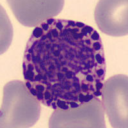

In [15]:
def predict_images(paths):
    paths = [Path(path) for path in paths]
    rows = []
    for start in range(0, len(paths), 32):
        group = paths[start:start + 32]
        pixels = []
        for path in group:
            image = tf.keras.utils.load_img(path, color_mode="rgb", target_size=(128, 128), interpolation="bilinear")
            pixels.append(tf.keras.utils.img_to_array(image))
        batch = np.stack(pixels)
        features = feature_model.predict(batch, batch_size=32, verbose=0)
        scaled = np.asarray(scaler.transform(features), dtype=np.float32)
        with threadpool_limits(limits=CONFIG["cpu_threads"]):
            ga_prediction = svm_ga.predict(scaled[:, inference_mask])
            all_prediction = svm_all.predict(scaled)
        dense_prediction = image_model.predict(batch, batch_size=32, verbose=0).argmax(axis=1)
        for path, selected_label, all_label, dense_label in zip(group, ga_prediction, all_prediction, dense_prediction):
            rows.append({"Image": path.name, "GA + SVM": CLASS_NAMES[int(selected_label)],
                         "All-feature SVM": CLASS_NAMES[int(all_label)], "DenseNet": CLASS_NAMES[int(dense_label)]})
    return pd.DataFrame(rows)

example_paths = [BUNDLE_DIR / "examples" / item["filename"] for item in model_info["examples"]]
example_predictions = predict_images(example_paths)
example_predictions.insert(1, "Dataset label", [item["class_name"] for item in model_info["examples"]])
example_predictions.to_csv(RESULT_DIR / "example_predictions.csv", index=False)
display(example_predictions)
display(DisplayImage(filename=str(example_paths[0]), width=160))


## 12. Optional: use your own image

Use a cropped image of one blood cell. Upload it with the notebook's file panel
and enter its path. In Colab, you can instead enable the upload button below.
The default skips the dialog so Run all completes without waiting for input.


In [16]:
MY_IMAGE_PATH = ""  # Example: "/content/blood_cell.png"
UPLOAD_WITH_COLAB_BUTTON = False
custom_paths = [Path(MY_IMAGE_PATH)] if MY_IMAGE_PATH else []
if UPLOAD_WITH_COLAB_BUTTON:
    try:
        from google.colab import files
    except ImportError as error:
        raise RuntimeError("On Kaggle, use its file panel and set MY_IMAGE_PATH.") from error
    custom_paths = [Path(name) for name in files.upload()]
if custom_paths:
    display(predict_images(custom_paths))
else:
    print("Optional upload skipped. Shared-checkpoint verification and example inference are complete.")


Optional upload skipped. Shared-checkpoint verification and example inference are complete.


## 13. Data-loading functions for optional experiments

The original image-level splits are retained, with the documented exact-overlap
rows excluded from training/validation. Row IDs remain attached to the data.
The image dataset shuffles paired images and labels only during training.


In [17]:
def load_data(path, audit_dir=None):
    """Keep the official test set; remove exact overlaps from train/validation."""
    path = Path(path)
    if file_digest(path, "md5") != "adace1e0ed228fccda1f39692059dd4c":
        raise ValueError("Expected the official, unmodified BloodMNIST 128 dataset")
    arrays, hashes, hashes_by_row, rows = {}, {}, {}, []
    with np.load(path, allow_pickle=False) as archive:
        for split, expected in [("train", 11959), ("val", 1712), ("test", 3421)]:
            x = archive[f"{split}_images"]
            y = archive[f"{split}_labels"].reshape(-1).astype(np.int64)
            assert x.shape == (expected, 128, 128, 3) and x.dtype == np.uint8
            assert y.shape == (expected,) and set(np.unique(y)) == set(range(8))
            ids = np.array([f"{split}_{i:05d}" for i in range(expected)])
            image_hashes = [hashlib.sha256(image.tobytes()).hexdigest() for image in x]
            hashes_by_row[split] = image_hashes
            hashes[split] = set(image_hashes)
            arrays[f"images_{split}"], arrays[f"y_{split}"], arrays[f"ids_{split}"] = x, y, ids
            rows.extend({"image_id": image_id, "split": split, "label": int(label),
                         "class_name": CLASS_NAMES[int(label)], "image_sha256": digest}
                        for image_id, label, digest in zip(ids, y, image_hashes))
    intersections = {f"{a}_{b}": len(hashes[a] & hashes[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
    removed = {}
    for split, forbidden in [("train", hashes["val"] | hashes["test"]), ("val", hashes["test"])]:
        keep = np.array([digest not in forbidden for digest in hashes_by_row[split]], dtype=bool)
        removed[split] = arrays[f"ids_{split}"][~keep].tolist()
        for prefix in ["images", "y", "ids"]:
            arrays[f"{prefix}_{split}"] = arrays[f"{prefix}_{split}"][keep]
        hashes[split] = {digest for digest, retain in zip(hashes_by_row[split], keep) if retain}
    after = {f"{a}_{b}": len(hashes[a] & hashes[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
    assert not any(after.values()), f"Exact duplicate images still cross splits: {after}"
    audit = {"dataset_sha256": file_digest(path), "official_md5_verified": True,
             "original_exact_image_duplicates_across_splits": intersections,
             "remaining_exact_image_duplicates_across_splits": after,
             "removed_duplicate_image_ids": removed, "official_test_set_unchanged": True,
             "split_sizes": {s: len(arrays[f"y_{s}"]) for s in ["train", "val", "test"]},
             "class_names": CLASS_NAMES,
             "split_scope": "Official image-level splits with exact train/validation overlaps removed. Test set unchanged. Patient-independent generalization is not established."}
    manifest = pd.DataFrame(rows)
    removed_ids = set(removed["train"]) | set(removed["val"])
    manifest["included"] = ~manifest.image_id.isin(removed_ids)
    if audit_dir:
        directory = Path(audit_dir)
        directory.mkdir(parents=True, exist_ok=True)
        manifest.to_csv(directory / "split_manifest.csv", index=False)
        (directory / "data_audit.json").write_text(json.dumps(audit, indent=2) + "\n")
    print("Removed exact overlap rows:", {s: len(v) for s, v in removed.items()}, flush=True)
    included = manifest.loc[manifest.included]
    print(pd.crosstab(included.class_name, included.split).to_string(), flush=True)
    return arrays, audit


In [18]:
def image_dataset(images, labels=None, batch_size=64, shuffle=False, seed=42):
    data = tf.data.Dataset.from_tensor_slices(images if labels is None else (images, labels))
    if shuffle:
        data = data.shuffle(min(len(images), 4096), seed=seed, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.deterministic = True
    options.threading.private_threadpool_size = 4
    data = data.with_options(options)
    return data.batch(batch_size).prefetch(2)


## 14. Optional: download the full dataset

Only `reextract` and `train` need this roughly 569 MB download. The project mirror
is byte-identical to the official BloodMNIST 128 archive and is checked by SHA-256
and the official MD5. The original source is
[MedMNIST+ on Zenodo](https://zenodo.org/records/10519652), under CC BY 4.0.


In [19]:
data = None
if RUN_MODE != "verify":
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    signature = {"mode": RUN_MODE, "config": CONFIG, "source_weights_sha256": model_info["exported_weights_sha256"]}
    signature_path = RUN_DIR / "experiment_config.json"
    if signature_path.exists():
        assert json.loads(signature_path.read_text()) == signature, "Choose a new EXPERIMENT_NAME for changed settings or a different mode."
    else:
        signature_path.write_text(json.dumps(signature, indent=2) + "\n")
    (RUN_DIR / "protocol.json").write_text(json.dumps(CONFIG, indent=2) + "\n")
if RUN_MODE in {"reextract", "train"}:
    info = asset_manifest["dataset"]
    dataset_path = download(release_url(asset_manifest, info["name"]), WORK_DIR / "data" / info["name"], info["sha256"], info["size"])
    data, experiment_audit = load_data(dataset_path, RUN_DIR)
else:
    print("Full dataset download skipped for mode:", RUN_MODE)


Full dataset download skipped for mode: verify


## 15. Optional: train the original DenseNet architecture

The classifier head is warmed up for 2 epochs, then DenseNet is fine-tuned for
up to 20 epochs with early stopping. Checkpoints are selected by validation accuracy.
Training can take substantially longer on a cloud GPU than on the project server.
For a fresh run, use a new experiment name. An interrupted run is never silently
treated as completed training.


In [20]:
def train_model(data, run_dir, config=None):
    config = dict(DEFAULT_CONFIG if config is None else config)
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)
    complete = run_dir / "training_complete.json"
    checkpoint = run_dir / "best_model.weights.h5"
    tf.keras.utils.set_random_seed(config["seed"])
    model, backbone = build_model(config["image_size"], weights=None if complete.exists() else "imagenet", seed=config["seed"])
    if complete.exists():
        record = json.loads(complete.read_text())
        assert record["config"] == config and record["checkpoint_sha256"] == file_digest(checkpoint)
        model.load_weights(checkpoint)
        print("Loaded completed checkpoint:", checkpoint, flush=True)
        return model
    if checkpoint.exists():
        raise RuntimeError("An incomplete run exists. Choose a new experiment directory for fresh training.")
    (run_dir / "protocol.json").write_text(json.dumps(config, indent=2) + "\n")
    train = image_dataset(data["images_train"], data["y_train"], config["batch_size"], True, config["seed"])
    validation = image_dataset(data["images_val"], data["y_val"], config["batch_size"])
    history_parts = []

    def compile_model(rate):
        model.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=rate, weight_decay=config["weight_decay"]),
                      loss="sparse_categorical_crossentropy", metrics=["accuracy"], jit_compile=False)

    def checkpoint_callback(threshold=None):
        return tf.keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_accuracy", mode="max",
                    save_best_only=True, save_weights_only=True, initial_value_threshold=threshold)

    start = time.monotonic()
    compile_model(config["warmup_learning_rate"])
    print("PHASE 1: train classifier head", flush=True)
    warmup = model.fit(train, validation_data=validation, epochs=config["warmup_epochs"], verbose=2,
                       callbacks=[checkpoint_callback()])
    history_parts.append(pd.DataFrame(warmup.history).assign(phase="warmup"))
    warmup_best = max(warmup.history["val_accuracy"])
    model.load_weights(checkpoint)
    backbone.trainable = True
    for layer in backbone.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    compile_model(config["finetune_learning_rate"])
    print("PHASE 2: fine-tune DenseNet121", flush=True)
    fine = model.fit(train, validation_data=validation, epochs=config["finetune_epochs"], verbose=2, callbacks=[
        checkpoint_callback(warmup_best),
        tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=config["early_stopping_patience"], min_delta=0.0005),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ])
    history_parts.append(pd.DataFrame(fine.history).assign(phase="finetune"))
    history = pd.concat(history_parts, ignore_index=True)
    history.insert(0, "epoch", np.arange(1, len(history) + 1))
    history.to_csv(run_dir / "training_history.csv", index=False)
    model.load_weights(checkpoint)
    model.save(run_dir / "best_model.keras")
    record = {"config": config, "checkpoint_sha256": file_digest(checkpoint),
              "best_validation_accuracy": float(history.val_accuracy.max()),
              "best_epoch": int(history.loc[history.val_accuracy.idxmax(), "epoch"]),
              "epochs_run": len(history), "training_seconds": time.monotonic() - start}
    complete.write_text(json.dumps(record, indent=2) + "\n")
    print("TRAINING COMPLETE", json.dumps(record), flush=True)
    return model


In [21]:
experiment_model = image_model
if RUN_MODE == "train":
    if not tf.config.list_physical_devices("GPU"):
        raise RuntimeError("Select a GPU, restart the kernel, and Run all before full training.")
    experiment_model = train_model(data, RUN_DIR, CONFIG)
elif RUN_MODE in {"ga", "reextract"}:
    shutil.copy2(BUNDLE_DIR / "densenet121.weights.h5", RUN_DIR / "best_model.weights.h5")
    print("Using the shared trained checkpoint.")
else:
    print("Backbone training skipped.")


Backbone training skipped.


## 16. Optional: extract features and verify the original head

Extraction never shuffles. Features, labels, and image IDs are saved together.
The original head must give matching predictions from extracted features and
from the complete image model. This checks that extraction preserves the
trained model's predictions.


In [22]:
def extract_features(model, data, run_dir, batch_size=64):
    """The prediction iterator never shuffles; save explicit row IDs and labels."""
    run_dir = Path(run_dir)
    extractor = tf.keras.Model(model.input, model.get_layer("deep_features").output)
    extractor.jit_compile = False
    arrays = {}
    for split in ["train", "val", "test"]:
        features = extractor.predict(image_dataset(data[f"images_{split}"], batch_size=batch_size), verbose=1)
        assert features.shape == (len(data[f"y_{split}"]), 1024) and np.isfinite(features).all()
        arrays[f"X_{split}"] = features
        arrays[f"y_{split}"] = data[f"y_{split}"].copy()
        arrays[f"ids_{split}"] = data[f"ids_{split}"].copy()
    np.savez_compressed(run_dir / "aligned_features.npz", **arrays)
    inputs = tf.keras.Input((1024,))
    x = inputs
    for name in ["head_dense", "head_dropout", "cell_class"]:
        x = model.get_layer(name)(x)
    original_head = tf.keras.Model(inputs, x)
    original_head.jit_compile = False
    head_probabilities = original_head.predict(arrays["X_test"], batch_size=batch_size, verbose=0)
    image_probabilities = model.predict(image_dataset(data["images_test"], batch_size=batch_size), verbose=1)
    np.testing.assert_allclose(head_probabilities, image_probabilities, rtol=2e-4, atol=2e-5)
    np.testing.assert_array_equal(head_probabilities.argmax(1), image_probabilities.argmax(1))
    np.savez_compressed(run_dir / "densenet_test_predictions.npz", probabilities=image_probabilities,
                        labels=arrays["y_test"], image_ids=arrays["ids_test"])
    parity = {"identical_classes": True, "maximum_probability_difference": float(np.max(np.abs(head_probabilities - image_probabilities))),
              "feature_width": 1024, "checkpoint_sha256": file_digest(run_dir / "best_model.weights.h5"),
              "note": "This is an extraction-equivalence check; test accuracy is reported only after GA selection is locked."}
    (run_dir / "feature_parity.json").write_text(json.dumps(parity, indent=2) + "\n")
    print("FEATURE ALIGNMENT AND HEAD PARITY PASSED", json.dumps(parity), flush=True)
    return arrays


In [23]:
arrays = saved_arrays
if RUN_MODE in {"reextract", "train"}:
    arrays = extract_features(experiment_model, data, RUN_DIR, CONFIG["batch_size"])
elif RUN_MODE == "ga":
    for name in ["aligned_features.npz", "densenet_test_predictions.npz", "data_audit.json", "split_manifest.csv"]:
        shutil.copy2(BUNDLE_DIR / name, RUN_DIR / name)
    print("Using saved, verified features; no image extraction is needed.")
else:
    print("Optional feature extraction skipped.")


Optional feature extraction skipped.

## 17. Fit the scaler and choose SVM regularization on validation data

The scaler is fitted on training features only. SVM C is chosen from 0.1, 1, and
10 using validation accuracy. The same selected C is used before and after GA.


In [24]:
def fit_scaler_and_choose_svm(arrays, run_dir, config=None):
    config = DEFAULT_CONFIG if config is None else config
    run_dir = Path(run_dir)
    scaler = StandardScaler().fit(arrays["X_train"])
    scaled = {s: np.asarray(scaler.transform(arrays[f"X_{s}"]), dtype=np.float32) for s in ["train", "val", "test"]}
    candidates = []
    with threadpool_limits(limits=config["cpu_threads"]):
        for c in config["svm_c_candidates"]:
            start = time.monotonic()
            model = SVC(C=c, kernel="rbf", gamma="scale", cache_size=512)
            model.fit(scaled["train"], arrays["y_train"])
            accuracy = accuracy_score(arrays["y_val"], model.predict(scaled["val"]))
            candidates.append({"C": c, "validation_accuracy": float(accuracy), "seconds": time.monotonic() - start})
            print("SVM VALIDATION", json.dumps(candidates[-1]), flush=True)
    chosen = max(candidates, key=lambda r: (r["validation_accuracy"], -r["C"]))
    pd.DataFrame(candidates).to_csv(run_dir / "svm_validation_search.csv", index=False)
    joblib.dump(scaler, run_dir / "feature_scaler.joblib")
    return scaler, scaled, float(chosen["C"])


In [25]:
if RUN_MODE != "verify":
    experiment_scaler, scaled, chosen_c = fit_scaler_and_choose_svm(arrays, RUN_DIR, CONFIG)
    print("Validation-selected SVM C:", chosen_c)
else:
    print("Validation search skipped; shared classifiers are already fitted.")


Validation search skipped; shared classifiers are already fitted.


## 18. Standard Genetic Algorithm

Each bit indicates whether a deep feature is kept. This uses ordinary tournament
selection, uniform crossover, bit mutation, and elitism. The all-feature candidate
is included in the initial population. The fitness is:

`0.99 × validation accuracy + 0.01 × fraction of features removed`.

Accuracy is prioritized, with a small reward for fewer features. The GA receives
training and validation arrays only. Every population, including the final one,
is evaluated. This is a standard project implementation, not a novelty claim.


In [26]:
def run_binary_ga(x_train, y_train, x_val, y_val, c=10.0, config=None):
    """Conventional tournament selection, uniform crossover, mutation and elitism.

    Only training and validation arrays are accepted. The all-feature candidate
    is included, and every generated population (including the last) is scored.
    """
    from concurrent.futures import ThreadPoolExecutor
    import os
    config = dict(DEFAULT_CONFIG if config is None else config)
    rng = np.random.default_rng(config["seed"])
    width = x_train.shape[1]
    assert x_val.shape[1] == width and len(x_train) == len(y_train) and len(x_val) == len(y_val)
    count, elites = config["ga_population"], config["ga_elites"]
    alpha = config["ga_accuracy_weight"]
    assert 0 < alpha <= 1 and 0 < elites < count
    population = [np.ones(width, dtype=bool)]
    for index in range(count - 1):
        mask = rng.random(width) < [0.25, 0.5, 0.75][index % 3]
        mask[rng.integers(width)] = True
        population.append(mask)
    cache, history = {}, []
    start = time.monotonic()

    def key(mask):
        return np.packbits(mask).tobytes()

    def score(mask):
        classifier = SVC(C=c, kernel="rbf", gamma="scale", cache_size=256)
        classifier.fit(x_train[:, mask], y_train)
        accuracy = float(accuracy_score(y_val, classifier.predict(x_val[:, mask])))
        return (float(alpha * accuracy + (1 - alpha) * (1 - mask.mean())), accuracy, int(mask.sum()))

    def ordering(mask):
        value = cache[key(mask)]
        return value[0], value[1], -value[2]

    best_mask = population[0].copy()
    workers = int(os.environ.get("BLOOD_GA_WORKERS", config["ga_workers"]))
    assert workers >= 1
    with threadpool_limits(limits=1), ThreadPoolExecutor(max_workers=workers) as pool:
        for generation in range(config["ga_generations"] + 1):
            pending = {key(mask): mask for mask in population if key(mask) not in cache}
            for mask_key, result in zip(pending, pool.map(score, pending.values())):
                cache[mask_key] = result
            population.sort(key=ordering, reverse=True)
            if ordering(population[0]) > ordering(best_mask):
                best_mask = population[0].copy()
            best_score, best_accuracy, selected = cache[key(best_mask)]
            history.append({"generation": generation, "fitness": best_score, "validation_accuracy": best_accuracy,
                            "selected_features": selected, "unique_masks_evaluated": len(cache), "seconds": time.monotonic() - start})
            print(f"GA generation {generation:02d}/{config['ga_generations']} | validation {best_accuracy:.4%} | features {selected}/{width} | fitness {best_score:.6f}", flush=True)
            if generation == config["ga_generations"]:
                break

            def parent():
                candidates = rng.choice(len(population), size=config["ga_tournament"], replace=False)
                return max((population[i] for i in candidates), key=ordering)

            children = [mask.copy() for mask in population[:elites]]
            while len(children) < count:
                first, second = parent(), parent()
                child = first.copy()
                if rng.random() < config["ga_crossover_probability"]:
                    swap = rng.random(width) < 0.5
                    child[swap] = second[swap]
                child ^= rng.random(width) < 1.0 / width
                if not child.any():
                    child[rng.integers(width)] = True
                children.append(child)
            population = children
    baseline = cache[key(np.ones(width, dtype=bool))]
    result = {"algorithm": "standard_binary_genetic_algorithm", "fitness": cache[key(best_mask)][0],
              "validation_accuracy": cache[key(best_mask)][1], "selected_features": int(best_mask.sum()),
              "total_features": width, "all_feature_validation_accuracy": baseline[1],
              "accuracy_weight": alpha, "svm_C": c, "unique_masks_evaluated": len(cache),
              "generations": config["ga_generations"], "population_size": count,
              "elapsed_seconds": time.monotonic() - start, "seed": config["seed"], "evaluation_workers": workers}
    return best_mask, result, pd.DataFrame(history)


In [27]:
def lock_selection(mask, ga_result, history, run_dir, config):
    """Persist all choices before reporting held-out test accuracy."""
    from datetime import datetime, timezone
    run_dir = Path(run_dir)
    np.save(run_dir / "ga_mask.npy", np.asarray(mask, dtype=bool))
    np.save(run_dir / "selected_feature_indices.npy", np.flatnonzero(mask))
    history.to_csv(run_dir / "ga_history.csv", index=False)
    (run_dir / "ga_result.json").write_text(json.dumps(ga_result, indent=2) + "\n")
    record = {"locked_at_utc": datetime.now(timezone.utc).isoformat(),
              "mask_sha256": file_digest(run_dir / "ga_mask.npy"),
              "features_sha256": file_digest(run_dir / "aligned_features.npz"),
              "checkpoint_sha256": file_digest(run_dir / "best_model.weights.h5"),
              "svm_C": ga_result["svm_C"], "config": dict(config),
              "selection_data": "training and validation only"}
    (run_dir / "selection_locked.json").write_text(json.dumps(record, indent=2) + "\n")


## 19. Optional: run GA and lock the selected mask


In [28]:
if RUN_MODE != "verify":
    selected_mask, ga_result, ga_history = run_binary_ga(scaled["train"], arrays["y_train"], scaled["val"], arrays["y_val"], chosen_c, CONFIG)
    lock_selection(selected_mask, ga_result, ga_history, RUN_DIR, CONFIG)
    display(ga_history.tail())
    print(json.dumps(ga_result, indent=2))
else:
    print("GA rerun skipped. The saved feature mask has been verified.")


GA rerun skipped. The saved feature mask has been verified.


## 20. New experiment results: compare before and after GA

**This is where your new run's results appear** when `RUN_MODE` is `ga`, `reextract`,
or `train`. Each classifier is fitted on all features and on the selected subset
using matching settings. The primary comparison is SVM; KNN, random forest, and
the neural head are additional project comparisons.

The new neural heads keep their own learned weights. No unrelated model weights
are mixed after training. The test set is evaluated after the GA mask is locked.
With `verify`, this optional fitting is skipped because steps 8–11 already verify
and demonstrate the shared trained model.


In [29]:
def build_feature_head(width, seed=42):
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.Input((width,)), tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dropout(0.3, seed=seed), tf.keras.layers.Dense(8, activation="softmax"),
    ])
    model.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"], jit_compile=False)
    return model


In [30]:
def evaluate_classifiers(arrays, scaled, mask, run_dir, c, config=None, head_epochs=60):
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.neighbors import KNeighborsClassifier
    config = DEFAULT_CONFIG if config is None else config
    run_dir = Path(run_dir)
    lock = json.loads((run_dir / "selection_locked.json").read_text())
    assert lock["mask_sha256"] == file_digest(run_dir / "ga_mask.npy")
    assert lock["features_sha256"] == file_digest(run_dir / "aligned_features.npz")
    assert lock["svm_C"] == c
    np.testing.assert_array_equal(mask, np.load(run_dir / "ga_mask.npy"))
    rows = []

    def record(name, subset, split, prediction, feature_count):
        labels = arrays[f"y_{split}"]
        rows.append({"classifier": name, "features": subset, "n_features": feature_count, "split": split,
                     "samples": len(labels), "correct": int((prediction == labels).sum()),
                     "accuracy": float(accuracy_score(labels, prediction)),
                     "balanced_accuracy": float(balanced_accuracy_score(labels, prediction)),
                     "macro_f1": float(f1_score(labels, prediction, average="macro", zero_division=0))})
        np.savez_compressed(run_dir / f"predictions_{name}_{subset}_{split}.npz", predictions=prediction,
                            labels=labels, image_ids=arrays[f"ids_{split}"])
        if split == "test":
            pd.DataFrame(confusion_matrix(labels, prediction, labels=np.arange(8)), index=CLASS_NAMES,
                         columns=CLASS_NAMES).to_csv(run_dir / f"confusion_{name}_{subset}.csv")
            report = classification_report(labels, prediction, labels=np.arange(8), target_names=CLASS_NAMES,
                                           output_dict=True, zero_division=0)
            (run_dir / f"report_{name}_{subset}.json").write_text(json.dumps(report, indent=2) + "\n")

    with threadpool_limits(limits=config["cpu_threads"]):
        for subset, selection in [("all", np.ones_like(mask)), ("ga_selected", mask)]:
            x_train, x_val, x_test = [scaled[s][:, selection] for s in ["train", "val", "test"]]
            models = {
                "SVM": SVC(C=c, kernel="rbf", gamma="scale", cache_size=512),
                "KNN": KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=config["cpu_threads"]),
                "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                    random_state=config["seed"], n_jobs=config["cpu_threads"]),
            }
            for name, classifier in models.items():
                print("Fitting", name, subset, int(selection.sum()), "features", flush=True)
                classifier.fit(x_train, arrays["y_train"])
                if name == "SVM":
                    joblib.dump(classifier, run_dir / f"svm_{subset}.joblib", compress=3)
                for split, x in [("val", x_val), ("test", x_test)]:
                    record(name, subset, split, classifier.predict(x), int(selection.sum()))
            print("Fitting NeuralHead", subset, flush=True)
            head = build_feature_head(int(selection.sum()), config["seed"])
            head_path = run_dir / f"head_{subset}.weights.h5"
            train = image_dataset(x_train, arrays["y_train"], 64, True, config["seed"])
            validation = image_dataset(x_val, arrays["y_val"], 64)
            history = head.fit(train, validation_data=validation, epochs=head_epochs, verbose=2, callbacks=[
                tf.keras.callbacks.ModelCheckpoint(str(head_path), monitor="val_accuracy", mode="max", save_best_only=True, save_weights_only=True),
                tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=8, min_delta=0.0005),
            ])
            pd.DataFrame(history.history).to_csv(run_dir / f"head_history_{subset}.csv", index=False)
            head.load_weights(head_path)
            for split, x in [("val", x_val), ("test", x_test)]:
                prediction = head.predict(image_dataset(x, batch_size=64), verbose=0).argmax(axis=1)
                record("NeuralHead", subset, split, prediction, int(selection.sum()))
    with np.load(run_dir / "densenet_test_predictions.npz") as saved:
        image_prediction = saved["probabilities"].argmax(axis=1)
        np.testing.assert_array_equal(saved["labels"], arrays["y_test"])
        np.testing.assert_array_equal(saved["image_ids"], arrays["ids_test"])
    dense_accuracy = float(accuracy_score(arrays["y_test"], image_prediction))
    result = pd.DataFrame(rows)
    assert len(result) == 16
    result.to_csv(run_dir / "classifier_comparison.csv", index=False)
    summary = {"densenet_test_accuracy": dense_accuracy, "test_images": len(arrays["y_test"]),
               "features_before": len(mask), "features_after": int(mask.sum()),
               "feature_reduction_percent": float(100 * (1 - mask.mean())),
               "selected_svm_C": c, "ga_selection_used_test_labels": False}
    for subset in ["all", "ga_selected"]:
        row = result.query("classifier == 'SVM' and features == @subset and split == 'test'").iloc[0]
        summary[f"svm_{subset}_test_accuracy"] = float(row.accuracy)
        summary[f"svm_{subset}_correct"] = int(row.correct)
    summary["svm_change_percentage_points"] = 100 * (summary["svm_ga_selected_test_accuracy"] - summary["svm_all_test_accuracy"])
    (run_dir / "run_complete.json").write_text(json.dumps(summary, indent=2) + "\n")
    print("FINAL TEST COMPARISON", flush=True)
    print(result.query("split == 'test'").pivot(index="classifier", columns="features", values="accuracy").to_string(), flush=True)
    print("RUN COMPLETE", json.dumps(summary), flush=True)
    return result, summary


In [31]:
new_summary = None
if RUN_MODE != "verify":
    new_comparison, new_summary = evaluate_classifiers(arrays, scaled, selected_mask, RUN_DIR, chosen_c, CONFIG)
    new_table = new_comparison.query("split == 'test'").pivot(index="classifier", columns="features", values="accuracy") * 100
    display(new_table.round(2))
    print(f"YOUR NEW RUN: GA + SVM test accuracy = {100 * new_summary['svm_ga_selected_test_accuracy']:.2f}%")
    print("Your run's files:", RUN_DIR)
    # Make the existing prediction helper use this new experiment from now on.
    image_model = experiment_model
    feature_model = tf.keras.Model(image_model.input, image_model.get_layer("deep_features").output)
    feature_model.jit_compile = False
    scaler = experiment_scaler
    inference_mask = selected_mask
    svm_all = joblib.load(RUN_DIR / "svm_all.joblib")
    svm_ga = joblib.load(RUN_DIR / "svm_ga_selected.joblib")
    print("Inference now uses YOUR new experiment. Rerun step 12 to predict your own image with it.")
else:
    print("No new training experiment requested. The shared-checkpoint scores are in step 8.")


No new training experiment requested. The shared-checkpoint scores are in step 8.


## 21. Save results and checkpoints

Download your results before ending the cloud session. In Colab, use the file
panel; on Kaggle, files under `/kaggle/working` are available as notebook outputs.
The verified-results ZIP contains the shared-model scores computed in this run.
An experiment mode also creates a separate ZIP with its trained weights, scaler,
SVMs, feature mask, and result tables.

These are benchmark results for blood-cell type classification. Higher accuracy
on BloodMNIST does not establish that it is a better medical model than the skin
classifier; the tasks and datasets differ. GA is not guaranteed to improve every
classifier or every fresh training run.


In [32]:
verification_summary = {
    "dataset": "BloodMNIST 128", "test_images": len(saved_arrays["y_test"]),
    "shared_svm_all_accuracy": float(verification.iloc[0]["Accuracy (%)"] / 100),
    "shared_svm_ga_accuracy": float(verification.iloc[1]["Accuracy (%)"] / 100),
    "shared_selected_features": int(saved_mask.sum()), "mode": RUN_MODE,
}
(RESULT_DIR / "verification_summary.json").write_text(json.dumps(verification_summary, indent=2) + "\n")
verified_zip = shutil.make_archive(str(WORK_DIR / "verified_results"), "zip", RESULT_DIR)
print("Shared-model verification complete:", verification_summary)
display(FileLink(verified_zip))
if new_summary is not None:
    experiment_zip = WORK_DIR / f"{EXPERIMENT_NAME}_checkpoint_and_results.zip"
    names = ["best_model.weights.h5", "svm_all.joblib", "svm_ga_selected.joblib", "feature_scaler.joblib",
             "ga_mask.npy", "selected_feature_indices.npy", "run_complete.json", "protocol.json",
             "selection_locked.json", "data_audit.json", "classifier_comparison.csv", "training_history.csv",
             "ga_history.csv", "experiment_config.json"]
    with zipfile.ZipFile(experiment_zip, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=1) as archive:
        for name in names:
            if (RUN_DIR / name).exists():
                archive.write(RUN_DIR / name, name)
    print("Your new experiment's checkpoint and results:")
    display(FileLink(str(experiment_zip)))


Shared-model verification complete: {'dataset': 'BloodMNIST 128', 'test_images': 3421, 'shared_svm_all_accuracy': 0.9891844489915229, 'shared_svm_ga_accuracy': 0.9874305758550131, 'shared_selected_features': 241, 'mode': 'verify'}


/tmp/blood_cell_notebook_online/blood_cell_work/verified_results.zip

## References and troubleshooting

- Dataset and license: [MedMNIST+ on Zenodo](https://zenodo.org/records/10519652),
  [MedMNIST project](https://medmnist.com/), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
- Yang et al., *MedMNIST v2*, Scientific Data 10, 41 (2023), and Yang, Shi and Ni,
  *MedMNIST Classification Decathlon*, ISBI (2021).
- Source microscopy data: Acevedo et al., *A dataset of microscopic peripheral
  blood cell images for development of automatic recognition systems*, Data in
  Brief 30, 105474 (2020), [DOI](https://doi.org/10.1016/j.dib.2020.105474).
- Download error: enable Internet, then rerun the download cell. Correct cached files are reused.
- Package error after installation: restart the session/kernel once, then run from step 1.
- GPU memory error: use `BATCH_SIZE = 32` or `16` and a fresh experiment name.
- Incomplete training checkpoint: choose a new experiment name for a fresh run;
  the notebook does not claim that an interrupted model finished training.
